In [23]:
# -- Import Packages
#!/usr/bin/env python
%matplotlib inline  

#ipython magic to make wiphy module autoreload
%load_ext autoreload
%autoreload 2

#import packages
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as st
import pandas as pd
import time
import scipy.integrate as spi
import os
from sklearn.metrics import auc 
import seaborn as sns
%matplotlib inline
import warnings
import seaborn as sns
from statannotations.Annotator import Annotator
from scipy.stats import mannwhitneyu

import numpy as np
import pandas as pd
import copy


warnings.filterwarnings("ignore")


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [24]:
#-------------------------------------#
# Defining function to retrieve parameters
#-------------------------------------#
def GetParams(parameters_df, ID, style = 'mode'):
    ''' 
    input:
        - data frame with parameter values as columns, individuals as rows
        - ID identifying individual of interest
        - style = 'mode' or 'mean' or 'SAEM' depending on which parameter values are preferred
    return:
        - dictionary with parameter names as key and parameter values as values
    '''
    i = ID
    cols = list(parameters_df)
    pid_params = parameters_df[parameters_df.id == i].copy()
    values = []
    keys = []
    for c in cols:
        if style in c:
            k = c.split('_')[0]
            keys.append(k)
            v = pid_params[c].values[0]
            values.append(v)
        for i,(v,k) in enumerate(zip(values, keys)):
            if 'log10' in k:
                values[i] = 10**v
                keys[i] = k.split('0')[1]

    params = dict(zip(keys, values))
    return params

In [60]:
#-------------------------------------#
# Defining Simulation function
#-------------------------------------#

def Simulate(func, param_order, param_dict, init, tend, N):
    '''
    input: 
        - func is a function that takes in the state variable, time and parameters and returns the derivative
        - params is a dictionary of the parameter values 
        - init is a dictionary of the initial condition to simulate from 
    return: 
        - trajectory simulated from init for tspan using func with given params
    '''
    # make parameter list in correct order
    # params = []
    # for k in param_order:
     #   params.append(param_dict[k])
    #build tspan
    # tspan = np.linspace(0,tend,N)
    
    params = [param_dict[k] for k in param_order]
    tspan = np.linspace(0, tend, N)
    
    # incorporate E0
    init_local = list(init)
    init_local[5] = param_dict['E0']

    # simulate using scipy integrate
    y = spi.odeint(
        func, 
        init_local, 
        tspan, 
        args = tuple(params))
    return tspan,y

# Set up initial condition
T_0 = 10**7
Ie_0 = 0;
Ip_0 = 0;
R_0 = 0;
V_0 = 0.075;
E_0 = 0;

init = [T_0, Ie_0, Ip_0, R_0, V_0, E_0]

 

In [45]:

#-------------------------------------#
# Write function for model simulation
#-------------------------------------#
def deriv(y, t, beta, phi, eta,gamma, delta,k, p,c,theta,h,r):
    T,Ie,Ip,R,V,E = y
        
    ddt_T = -beta*T*V - phi*Ip*T + eta*R
    ddt_Ie = beta*T*V - gamma*Ie
    ddt_Ip = gamma*Ie - delta*Ip - k*Ip*E
    ddt_R = phi*Ip*T -eta*R
    ddt_V = p*Ip-c*V
    ddt_E = theta*E*Ip**h/(Ip**h+r**h)

    return ddt_T, ddt_Ie, ddt_Ip, ddt_R, ddt_V, ddt_E

param_order = ['beta', 'phi','eta','gamma', 
                         'delta','k','p','c','theta','h','r']

In [136]:
#-------------------------------------#
# Defining SimulateTreatment function
#-------------------------------------#
def SimulateTreatment(
    func,
    param_order,
    param_dict,
    initTreatment,
    tend,
    N,
    treat_start,
    treat_end,
    avg_efficacy
):
    params = [param_dict[k] for k in param_order]

    # Must match derivOseltamivir's argument order:
    # Avgepsilon, treat_start, treat_end
    params.extend([avg_efficacy, treat_start, treat_end])

    tspan = np.linspace(0, tend, N)

    init_local = list(initTreatment)
    init_local[6] = param_dict['E0']

    y = spi.odeint(
        func,
        init_local,
        tspan,
        args=tuple(params)
    )

    return tspan, y

# Set up initial condition
T_0 = 10**7
Ie_0 = 0;
Ip_0 = 0;
R_0 = 0;
Vb_0 = 0
V_0 = 0.075;
E_0 = 0;


initTreatment = [T_0, Ie_0, Ip_0, R_0, Vb_0, V_0, E_0]


In [54]:
def SimulateTreatment(func, param_order, param_dict, initTreatment, tend, N, treat_start, treat_end):
    '''
    input: 
        - func is a function that takes in the state variable, time and parameters and returns the derivative
        - param_order: list - parameter names in the order expected by func
        - param_dict: a dictionary of individual-specific parameter values 
        - initTreatment: list - a dictionary of the initial condition to simulate from 
        - tend: float -- end time
        - N: int -- number of time points
        - treat_start: float -- Treatment start time
        - treat_end: float -- Treatment end time
    return: 
        - trajectory simulated from init for tspan using func with given params
    '''
    _
    # Make a copy so the original initial conditions are not modified
    #init = initTreatment.copy()
    
    # make parameter list in correct order
    params = []
    for k in param_order:
        params.append(param_dict[k])
        
    # add treatment parameters
    params.append(treat_start)
    params.append(treat_end)
    #params.append(avg_efficacy)
    
    # build tspan
    tspan = np.linspace(0,tend,N)
    
    # incorporate E0
    # initTreatment[6] = param_dict['E0']
    
    # Set individual E0
    initTreatment[6] = param_dict['E0']
    
    # simulate using scipy integrate
    y = spi.odeint(func, 
                   initTreatment,   #init = initial conditions without Vb compartment
                   tspan, 
                   args = tuple(params))
    return tspan,y
    
Vb_0 = 0
initTreatment = [T_0, Ie_0, Ip_0, R_0, Vb_0, V_0, E_0]

In [137]:
#-------------------------------------#
# Defining oseltamivir model
#-------------------------------------#
kcl = 2.079 #8 hour half-life of oseltamivir
def derivOseltamivir(y, t, beta, phi, eta, gamma, delta, k, p, c, theta, h, r, Avgepsilon, treat_start, treat_end):
   
    T,Ie,Ip,R,Vb,V,E = y
    
    if t > treat_start and t < treat_end:
        # treatment between start and end time
        eps = Avgepsilon
    elif t > treat_end:
        # nonlinear, exponential saturation decay of efficacy after treatment ends
        # kcl = 2.079 --> 8 hour half-life of oseltamivir
        eps = (Avgepsilon * np.exp(-(kcl)*(t-treat_end)))/(Avgepsilon * (np.exp(-kcl * (t-treat_end))-1)+1)
    else:    
        # before treatment starts 
        eps = 0
        
    ddt_T = -beta*T*V - phi*Ip*T + eta*R
    ddt_Ie = beta*T*V - gamma*Ie
    ddt_Ip = gamma*Ie - delta*Ip - k*Ip*E
    ddt_R = phi*Ip*T - eta*R
    ddt_Vb = eps*p*Ip - (delta + k*E)*Vb
    ddt_V = (1-eps)*p*Ip - c*V
    ddt_E = theta*E*Ip**h/(Ip**h+r**h)

    return ddt_T, ddt_Ie, ddt_Ip, ddt_R, ddt_Vb,ddt_V, ddt_E

param_order_oselt = ['beta', 'phi','eta','gamma', 
                     'delta','k','p','c',
                     'theta','h','r','Avgepsilon'
                     #'treat_start', 'treat_end'
                    ]


In [280]:
# Read in placebo-treated volunteer data
#------------------------------#
# Monolix Results
#------------------------------#
#------------------------------#
# File: Fitting to viral dynamics model 
# Chosen best-fit model parameters: Fixed c, beta, h parameters - Pre-run ##
# Fixed Param: fraction of bound virus = f
#------------------------------#

M4a_shifted_Hill8_fixed_c_Owens = "~/OneDrive - Fred Hutch Cancer Center/IAV Data/Monolix/Truncated Fittings/Projects/Test Models/Shifted Bounds - M4a/M4a_shifted_Hill8_fixed_c_Owens/IndividualParameters"
file_path = os.path.join(M4a_shifted_Hill8_fixed_c_Owens, "estimatedIndividualParameters.txt")

# Chosen (best-fit) estimated viral dynamics parameters read in 
vd_parameters_df = pd.read_csv(file_path, header = 0, sep = ",")

#------------------------------#
# File: Fitting to Oselt-volunteers treated with 75mg - Run 1 (lowest AIC) ##
# estimated parameters for placebo and 75mg-oselt-treated cohorts 
#------------------------------#
M4a_oselt_fit = "~/OneDrive - Fred Hutch Cancer Center/IAV Data/Monolix/Truncated Fittings/Projects/Oselt_Treatment/M4a_shifted_Hill8_oseltamivir_f_0.75/Assessment/Assessment_001/Assessment_001/IndividualParameters"
oselt_file_path = os.path.join(M4a_oselt_fit, "estimatedIndividualParameters.txt")

# Read in: Estimated oselt-treated parameters for all placebo and oselt-treated fitting results 
# parameter estimated for viral dynamics model 
parameters_df = pd.read_csv(oselt_file_path, header = 0, sep = ",")

#------------------------------#
# treated = 1; placebo = 0
#colorDict = {0:'dodgerblue',1:'tab:orange'}
# Using estimated treatment model to separate into placebo vs. oseltamivir estimated parameters
#------------------------------#
placebo_params_df = parameters_df[parameters_df['drug_concentration'].astype(str).str.strip() == '0'].copy()

oselt_params_df = parameters_df[parameters_df['drug_concentration'].astype(str).str.strip() == '75 mg'].copy()

#------------------------------#
# Identify IDs: volunteer observed vl data
#------------------------------#
# placebo n = 44 and oseltamivir (75mg) treated n = 39 volunteers; totalling n = 83 volunteers
oselt_placebo_df = pd.read_csv("~/OneDrive - Fred Hutch Cancer Center/IAV Data/Monolix/Truncated Fittings/Projects/placebo_75oselt.csv")

# volunteer observed vl data
placebo_only_df = pd.read_csv("~/OneDrive - Fred Hutch Cancer Center/IAV Data/Data_IAV Model/FLU_ALL_un_censored.csv")

# Data of oselt-treated volunteer only 
oselt_only_df = pd.read_csv("~/OneDrive - Fred Hutch Cancer Center/IAV Data/Monolix/Truncated Fittings/Projects/treated_75oselt.csv")

IDs = oselt_placebo_df.ID.unique()
IDs_placebo = placebo_only_df.ID.unique()
IDs_oselt = oselt_only_df.ID.unique()


#len(IDs)                         # n = 83 placebo and oselt-treated volunteers for simulation 
print(len(IDs)) 
print(len(IDs_placebo))            # n = 44
print(len(IDs_oselt))              # n = 39
#print(oselt_placebo_df)


83
44
39


In [48]:
#Calculating the observed NEJM data difference with of the placebo, oselt-, and balox-treated (mean) data
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt                    # for plotting 
from sklearn.metrics import r2_score               # for calculating R^2 

# ---------------------------------
# Observed data: NEJM Digitized Mean Data
# ---------------------------------
'''
"The mean (±SD) viral loads on day 1 (before the initiation of the trial regimen) 
were 5.79±1.87 log10 50% tissue-culture (TCID50) per milliliter in the baloxavir group,
5.56±1.89 log10 50% tissue-culture infective dose (TCID50) per milliter in the placebo group,
5.94±1.69 log10 TCID50 per milliliter in the oseltamivir group

LOD = 0.7 TCID50 
'''
# Adjust the timing of enrollment/baseline measurement to align untreated trajectories with placebo group
# Hayden 2018 NEJM (approximated) time points of change from baseline in Phase 3 trial (Figure 3):

time_points = np.array([0, 1, 2, 3, 4, 
                        #5, 6, 9
                       ])       # Day 0 = Day 1 before the initiation of the trial regimen in NEJM paper

# -----------------
# Digitized data
# -----------------
observed_Placebo_Mean = (np.array([0, -1.2,-2.9,-3.34,-4.47, -4.49, -4.88]))
observed_Balox_Mean   = (np.array([0, -4.4, -4.9, -4.5, -4.9, -4.6, -5.0]))       # greater viral load reduction for baloxavir by day 1
observed_Oselt_Mean   = np.array([0, -2.5, -4.2, -4.6, -5, -4.8, -5.2])

# -----------------
# Given NEJM data: mean viral load on day 1 (before the initiation of the trial regimen):
# reverting to viral load, if needed
# -----------------
#placebo_baseline = 5.56          # SD: +/- 1.89 
#oselt_baseline = 5.94            # SD: +/- 1.69
#balox_baseline = 5.79            # SD: +/1 1.87

# ----------
# If needed: Revert back to viral load - Digitized NEJM data 
# ----------
#Placebo_VL = placebo_baseline + Placebo_Mean 
#Oselt_VL = oselt_baseline + Oselt_Mean 
#Balox_VL = balox_baseline + Balox_Mean 

# -----------------
# Observed Data: Calculate the difference of observed data
# vl change of balox - placebo
# ----------------
observed_difference = observed_Oselt_Mean - observed_Placebo_Mean    
# results should be the same for the two above expressions

# subtraction order of operating but should yield the same results
print("\n NEJM Observed Oseltamivir - Placebo Mean Difference:")
for day, diff in zip(time_points, observed_difference):
    print(f"Day {day}: {diff:.3f}")


print(f"Digitized Placebo Mean:", observed_Placebo_Mean)
print(f"Digitized Oselt Mean:", observed_Oselt_Mean)


 NEJM Observed Oseltamivir - Placebo Mean Difference:
Day 0: 0.000
Day 1: -1.300
Day 2: -1.300
Day 3: -1.260
Day 4: -0.530
Digitized Placebo Mean: [ 0.   -1.2  -2.9  -3.34 -4.47 -4.49 -4.88]
Digitized Oselt Mean: [ 0.  -2.5 -4.2 -4.6 -5.  -4.8 -5.2]


In [281]:
## Running simulation for placebo
# PLACEBO SIMULATION
# Calculate individual and mean viral-load changes from untreated peak
# across f x efficacy combinations

def simulate_placebo(
    IDs_placebo,
    vd_parameters_df, #placebo_params_df,
    f_range=np.arange(0.0, 1.01, 0.25),
    avgepsilon_range=np.append(np.arange(0.5, 1.01, 0.05), 0.99),
    days_to_analyze=[0, 1, 2, 3, 4, 5, 6, 9]
):
    """
    Simulate untreated/placebo viral-load trajectories.

    For each individual:
      1. Simulate untreated viral load.
      2. Find peak viral load and peak time.
      3. Calculate log10 viral-load changes from peak at specified days.
      4. Store results for each f x efficacy x day combination.

    Returns
    -------
    placebo_results_df : DataFrame
        One row per individual, f, efficacy, and day.
        Includes peak information and viral-load changes.

    placebo_mean_df : DataFrame
        Mean log10 viral-load change for each f x efficacy x day.

    individual_reductions : dict
        Dictionary of individual-level results.
    """

    all_results = []

    # -----------------------------------------------------
    # Loop through individuals
    # -----------------------------------------------------
    for ID in IDs_placebo:

        # Get individual parameter estimates
        params_dict = GetParams(
            vd_parameters_df, #placebo_params_df, # vd_parameters_df, #
            ID,
            style='mode'
        )

        # -------------------------------------------------
        # Simulate untreated/placebo viral dynamics
        # -------------------------------------------------
        t, y = Simulate(
            deriv,
            param_order,
            copy.deepcopy(params_dict),
            init,
            40,
            10000
        )


        # Log10 untreated viral load
        V_untreated = np.log10(
            np.maximum(y[:, 4], 0.01)
        )

        # -------------------------------------------------
        # Find untreated peak viral load and peak time
        # -------------------------------------------------
        pk_ind = np.argmax(V_untreated)

        tpk = t[pk_ind]
        V0_untreated = V_untreated[pk_ind]
        VL_peak = y[pk_ind, 4]

        # -------------------------------------------------
        # Loop through f x efficacy combinations
        # -------------------------------------------------
        for f in f_range:

            for efficacy in avgepsilon_range:

                # -----------------------------------------
                # Calculate viral load at each requested day
                # relative to the individual's untreated peak
                # -----------------------------------------
                for day in days_to_analyze:

                    target_time = tpk + day

                    idx = np.argmin(
                        np.abs(t - target_time)
                    )

                    viral_load = V_untreated[idx]
                    viral_load_raw = y[idx, 4]

                    # Change relative to untreated peak
                    viral_load_change = (
                        viral_load - V0_untreated
                    )

                    all_results.append({
                        'ID': ID,
                        'f': f,
                        'Efficacy': efficacy,
                        'Day': day,
                        'Peak time': tpk,
                        'Peak viral load': VL_peak,
                        'Peak log10 viral load': V0_untreated,
                        'Time': t[idx],
                        'Viral load': viral_load_raw,
                        'Log10 viral load': viral_load,
                        'Log10 change from baseline': viral_load_change
                    })

    # -----------------------------------------------------
    # Combine individual results into a DataFrame
    # -----------------------------------------------------
    placebo_results_df = pd.DataFrame(all_results)

    # -----------------------------------------------------
    # Calculate mean change across individuals
    # for each f x efficacy x day combination
    # -----------------------------------------------------
    placebo_mean_df = (
        placebo_results_df
        .groupby(['f', 'Efficacy', 'Day'], as_index=False)
        ['Log10 change from baseline']
        .mean()
        .rename(columns={
            'Log10 change from baseline': 'Mean log10 change from baseline'
        })
    )

    # -----------------------------------------------------
    # Store individual results by f x efficacy combination
    # -----------------------------------------------------
    individual_reductions = {}

    for f in f_range:
        for efficacy in avgepsilon_range:

            subset = placebo_results_df[
                np.isclose(placebo_results_df['f'], f)
                & np.isclose(placebo_results_df['Efficacy'], efficacy)
            ]

            individual_reductions[(f, efficacy)] = (
                subset.pivot(
                    index='ID',
                    columns='Day',
                    values='Log10 change from baseline'
                )
            )

    return placebo_results_df, placebo_mean_df, individual_reductions

In [282]:
placebo_results_df, placebo_mean_df, individual_reductions = (
    simulate_placebo(
        IDs_placebo=IDs_placebo,
        #placebo_params_df = placebo_params_df,       # param_df: using 'Oselt_Treatment/M4a_shifted_Hill8_oseltamivir_f_0.75'
        vd_parameters_df = vd_parameters_df, 
        # param using estimated viral dynamics model parameters
        f_range=np.arange(0.0, 1.01, 0.25),
        avgepsilon_range=np.append(
            np.arange(0.5, 1.01, 0.05), 0.99
        ),
        days_to_analyze=[0, 1, 2, 3, 4, 
                         #5, 6, 9
                        ]
    )
)

In [237]:
# individual simulated results
display(placebo_results_df.head(20))

# mean placebo and vl drop from baseline results
display(placebo_mean_df.head(10))
display(placebo_mean_df.tail(10))   # showing f = 1, eps = 1

,ID,f,Efficacy,Day,Peak time,Peak viral load,Peak log10 viral load,Time,Viral load,Log10 viral load,Log10 change from baseline
0,4A,0.0,0.50,0,2.056206,26102.659864,4.416685,2.056206,2.610266e+04,4.416685,0.000000
1,4A,0.0,0.50,1,2.056206,26102.659864,4.416685,3.056306,1.960436e+03,3.292353,-1.124332
2,4A,0.0,0.50,2,2.056206,26102.659864,4.416685,4.056406,1.549723e+01,1.190254,-3.226431
3,4A,0.0,0.50,3,2.056206,26102.659864,4.416685,5.056506,8.521656e-02,-1.069476,-5.486161
4,4A,0.0,0.50,4,2.056206,26102.659864,4.416685,6.056606,7.457335e-04,-2.000000,-6.416685
5,4A,0.0,0.50,5,2.056206,26102.659864,4.416685,7.056706,7.054883e-06,-2.000000,-6.416685
6,4A,0.0,0.50,6,2.056206,26102.659864,4.416685,8.056806,6.873197e-08,-2.000000,-6.416685
7,4A,0.0,0.50,9,2.056206,26102.659864,4.416685,11.057106,6.742475e-14,-2.000000,-6.416685
8,4A,0.0,0.55,0,2.056206,26102.659864,4.416685,2.056206,2.610266e+04,4.416685,0.000000
9,4A,0.0,0.55,1,2.056206,26102.659864,4.416685,3.056306,1.960436e+03,3.292353,-1.124332


,f,Efficacy,Day,Mean log10 change from baseline
0,0.0,0.50,0,0.000000
1,0.0,0.50,1,-0.854089
2,0.0,0.50,2,-2.258794
3,0.0,0.50,3,-3.360429
4,0.0,0.50,4,-3.988166
5,0.0,0.50,5,-4.464714
6,0.0,0.50,6,-4.749224
7,0.0,0.50,9,-4.967700
8,0.0,0.55,0,0.000000
9,0.0,0.55,1,-0.854089


,f,Efficacy,Day,Mean log10 change from baseline
470,1.0,0.99,6,-4.749224
471,1.0,0.99,9,-4.967700
472,1.0,1.00,0,0.000000
473,1.0,1.00,1,-0.854089
474,1.0,1.00,2,-2.258794
475,1.0,1.00,3,-3.360429
476,1.0,1.00,4,-3.988166
477,1.0,1.00,5,-4.464714
478,1.0,1.00,6,-4.749224
479,1.0,1.00,9,-4.967700


In [284]:
## SImulated results of placebo volunteers using viral dyanmics model estimated parameters
## params_dic = 'placebo_params_df'
# mean placebo and vl drop from baseline results
display(placebo_mean_df.head(10)) 
display(placebo_mean_df.tail(10))   # showing f = 1, eps = 1

,f,Efficacy,Day,Mean log10 change from baseline
0,0.0,0.50,0,0.000000
1,0.0,0.50,1,-0.854089
2,0.0,0.50,2,-2.258794
3,0.0,0.50,3,-3.360429
4,0.0,0.50,4,-3.988166
5,0.0,0.55,0,0.000000
6,0.0,0.55,1,-0.854089
7,0.0,0.55,2,-2.258794
8,0.0,0.55,3,-3.360429
9,0.0,0.55,4,-3.988166


,f,Efficacy,Day,Mean log10 change from baseline
290,1.0,0.99,0,0.000000
291,1.0,0.99,1,-0.854089
292,1.0,0.99,2,-2.258794
293,1.0,0.99,3,-3.360429
294,1.0,0.99,4,-3.988166
295,1.0,1.00,0,0.000000
296,1.0,1.00,1,-0.854089
297,1.0,1.00,2,-2.258794
298,1.0,1.00,3,-3.360429
299,1.0,1.00,4,-3.988166


In [242]:
## SImulated results of placebo volunteers using viral dyanmics model estimated parameters
## params_dic = 'vd_parameters_df'
# mean placebo and vl drop from baseline results
display(placebo_mean_df.head(10)) 
display(placebo_mean_df.tail(10))   # showing f = 1, eps = 1

,f,Efficacy,Day,Mean log10 change from baseline
0,0.0,0.50,0,0.000000
1,0.0,0.50,1,-0.854089
2,0.0,0.50,2,-2.258794
3,0.0,0.50,3,-3.360429
4,0.0,0.50,4,-3.988166
5,0.0,0.55,0,0.000000
6,0.0,0.55,1,-0.854089
7,0.0,0.55,2,-2.258794
8,0.0,0.55,3,-3.360429
9,0.0,0.55,4,-3.988166


,f,Efficacy,Day,Mean log10 change from baseline
290,1.0,0.99,0,0.000000
291,1.0,0.99,1,-0.854089
292,1.0,0.99,2,-2.258794
293,1.0,0.99,3,-3.360429
294,1.0,0.99,4,-3.988166
295,1.0,1.00,0,0.000000
296,1.0,1.00,1,-0.854089
297,1.0,1.00,2,-2.258794
298,1.0,1.00,3,-3.360429
299,1.0,1.00,4,-3.988166


In [243]:
# save the simulated difference results to a .csv file
placebo_mean_df.to_csv(
    'placebo_mean_simulated_VL_differences.csv',
    index=False
)

In [285]:
# OSELT SIMULATION
# Calculate individual and mean viral-load changes from baseline
# across f x efficacy combinations

import numpy as np
import pandas as pd


def simulate_oselt(
    IDs_oselt,
    oselt_params_df,
    f_range=np.arange(0.0, 1.01, 0.25),                             # f: 0 - 1 by 0.25 increments
    avgepsilon_range=np.append(np.arange(0.5, 1.01, 0.05), 0.99),   # eps: 50% - 100% and 99%
    days_to_analyze=[0, 1, 2, 3, 4 
                     ,5 , 6, 9
                    ]
):
    """
    Simulate oseltamivir-treated viral-load trajectories.

    For each individual:
      1. Simulate untreated viral load.
      2. Find untreated peak time and peak viral load.
      3. Start treatment at the untreated peak.
      4. Simulate treatment for each f x efficacy combination.
      5. Calculate treated viral load relative to treated baseline
         at the untreated peak time.

    Returns
    -------
    oselt_results_df : DataFrame
        INDIVIDUAL-level results for each f x efficacy x day.

    oselt_mean_df : DataFrame
        MEAN log10 viral-load change for each f x efficacy x day.

    individual_reductions : dict
        Individual-level reductions indexed by (f, efficacy).
    """

    all_results = []

    treat_start = 0
    treat_end_O = 5

    # -----------------------------------------------------
    # Loop through individuals
    # -----------------------------------------------------
    for ID in IDs_oselt:

        # retrieve corresponding parameter values from the read in file 
        params_dict = GetParams(
            oselt_params_df,      #estimated model parameters from fitted treatment model
            ID,
            style='mode'
        )

        # -------------------------------------------------
        # Simulate untreated viral dynamics to determine peak
        # -------------------------------------------------
        #t, y = Simulate(
        #    deriv,
        #    param_order,
        #    params_dict,
        #    init,
        #    40,
        #    10000
        #)

        t, y = Simulate(
            deriv,
            param_order,
            copy.deepcopy(params_dict),
            list(init),
            40,
            10000
        )

        # log-transform simulated viral load peak value (column y[:, 4] = V from the Simulate(function) results)
        V_untreated = np.log10(np.maximum(y[:, 4], 0.01))

        # Find untreated peak
        pk_ind = np.argmax(V_untreated)
        # Find time of peak 
        tpk = t[pk_ind]
        # Set as initial/baseline value 
        V0_untreated = V_untreated[pk_ind]
        VL_peak = y[pk_ind, 4]

        # Treatment timing relative to untreated peak
        treat_start_temp = tpk + treat_start
        treat_end_O_temp = tpk + treat_end_O

        # -------------------------------------------------
        # Loop through f x efficacy combinations
        # -------------------------------------------------
        for f in f_range:

            for efficacy in avgepsilon_range:

                # Simulate oseltamivir treatment
                ttO, ytO = SimulateTreatment(
                    derivOseltamivir,
                    param_order, # param_order_oselt,
                    copy.deepcopy(params_dict), 
                    initTreatment.copy(),
                    40,
                    10000,
                    treat_start_temp,
                    treat_end_O_temp,
                    efficacy
                )

                #ttO, ytO = SimulateTreatment(
                #    derivOseltamivir,
                #    param_order, #param_order_oselt,   #param_order
                #    copy.deepcopy(params_dict),
                #    list(initTreatment),
                #    40,
                #    10000,
                #    treat_start_temp,
                #    treat_end_O_temp,
                #    efficacy
                #)

                print("ID:", ID, "f:", f, "efficacy:", efficacy)
                print("Treatment window:", treat_start_temp, treat_end_O_temp)
                print("Initial treated state:", ytO[0])
                print("All values finite:", np.isfinite(ytO).all())
                print("Minimum state by column:", np.min(ytO, axis=0))
                print("Maximum state by column:", np.max(ytO, axis=0))
                
                # Total treated viral load: Vu + f * Vb 
                # where simulated result columns:  0: ddt_T, 1: ddt_Ie, 2: ddt_Ip, 3: ddt_R, 4: ddt_Vb, 5: ddt_V, 6: ddt_E
                VL_O = ytO[:, 5] + f * ytO[:, 4]
                
                print("Minimum raw total viral load:", np.min(VL_O))
                print("Maximum raw total viral load:", np.max(VL_O))

                V_O = np.log10(np.maximum(VL_O, 0.01))

                # Treated baseline at untreated peak time
                baseline_idx = np.argmin(
                    np.abs(ttO - tpk)
                )
                V0_O = V_O[baseline_idx]

                # -------------------------------------------------
                # Calculate treated viral load at each day
                # -------------------------------------------------
                for day in days_to_analyze:

                    target_time = tpk + day

                    idx = np.argmin(
                        np.abs(ttO - target_time)
                    )

                    viral_load = V_O[idx]
                    viral_load_raw = VL_O[idx]

                    # Change from treated baseline
                    viral_load_change = viral_load - V0_O

                    all_results.append({
                        'ID': ID,
                        'f': f,
                        'Efficacy': efficacy,
                        'Day': day,
                        'Untreated peak time': tpk,
                        'Untreated peak viral load': VL_peak,
                        'Untreated peak log10 viral load': V0_untreated,
                        'Treated baseline log10 viral load': V0_O,
                        'Time': ttO[idx],
                        'Viral load': viral_load_raw,
                        'Log10 viral load': viral_load,
                        'Log10 change from baseline': viral_load_change
                    })

    # -----------------------------------------------------
    # Combine individual results
    # -----------------------------------------------------
    oselt_results_df = pd.DataFrame(all_results)

    # -----------------------------------------------------
    # Calculate mean change across individuals
    # -----------------------------------------------------
    oselt_mean_df = (
        oselt_results_df
        .groupby(['f', 'Efficacy', 'Day'], as_index=False)
        ['Log10 change from baseline']
        .mean()
        .rename(columns={
            'Log10 change from baseline':
                'Mean log10 change from baseline'
        })
    )

    # -----------------------------------------------------
    # Store individual reductions by combination
    # -----------------------------------------------------
    individual_reductions = {}

    for f in f_range:
        for efficacy in avgepsilon_range:

            subset = oselt_results_df[
                np.isclose(oselt_results_df['f'], f)
                & np.isclose(
                    oselt_results_df['Efficacy'], efficacy
                )
            ]

            individual_reductions[(f, efficacy)] = (
                subset.pivot(
                    index='ID',
                    columns='Day',
                    values='Log10 change from baseline'
                )
            )

    return oselt_results_df, oselt_mean_df, individual_reductions

In [211]:
oselt_results_df, oselt_mean_df, oselt_individual_reductions = (
    simulate_oselt(
        IDs_oselt=IDs_oselt,
        oselt_params_df=oselt_params_df,
        f_range=np.arange(0.0, 1.01, 0.25),
        avgepsilon_range=np.append(np.arange(0.5, 1.01, 0.05), 0.99),
        days_to_analyze=[0, 1, 2, 3, 4,
                         #5, 6, 9
                        ]
    ))

ID: 19B-A f: 0.0 efficacy: 0.5
Treatment window: 4.14041404140414 9.14041404140414
Initial treated state: [1.00000e+07 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00 7.50000e-02
 2.27429e+01]
All values finite: True
Minimum state by column: [ 4.16892577e+06 -3.02857810e-13 -4.83410802e-14 -6.00363931e-10
 -1.31557144e-13 -1.58231603e-13  2.27429000e+01]
Maximum state by column: [1.00000000e+07 1.78468301e+03 1.89955450e+03 5.82082584e+06
 4.32553368e+03 4.96537527e+03 3.56675146e+03]
Minimum raw total viral load: -1.5823160330244588e-13
Maximum raw total viral load: 4965.375270870503
ID: 19B-A f: 0.0 efficacy: 0.55
Treatment window: 4.14041404140414 9.14041404140414
Initial treated state: [1.00000e+07 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00 7.50000e-02
 2.27429e+01]
All values finite: True
Minimum state by column: [ 4.16892577e+06 -2.83602424e-13 -4.88060023e-14 -5.83287072e-10
 -7.12528386e-16 -1.57588206e-13  2.27429000e+01]
Maximum state by column: [1.00000000e+07 1.7846235

In [288]:
# Using the dataframe of mean vl chnages from baseline
# merge by f, eps, and day
# subtract the placebo mean from the oselt-mean change
# --------------------------------------------------
display(oselt_mean_df.head(10))      # mean results
display(oselt_mean_df.tail(10))      # mean results
#display(oselt_results_df.head(20))    # individual simulated results
#display(placebo_mean_df.head(10))     # simulated placebo results 



,f,Efficacy,Day,Mean log10 change from baseline
0,0.0,0.50,0,0.000000
1,0.0,0.50,1,-1.571854
2,0.0,0.50,2,-3.520514
3,0.0,0.50,3,-4.887950
4,0.0,0.50,4,-5.311635
5,0.0,0.55,0,0.000000
6,0.0,0.55,1,-1.684770
7,0.0,0.55,2,-3.667217
8,0.0,0.55,3,-4.954265
9,0.0,0.55,4,-5.346109


,f,Efficacy,Day,Mean log10 change from baseline
290,1.0,0.99,0,0.000000
291,1.0,0.99,1,-2.542529
292,1.0,0.99,2,-4.995676
293,1.0,0.99,3,-5.447030
294,1.0,0.99,4,-5.492950
295,1.0,1.00,0,0.000000
296,1.0,1.00,1,-2.583481
297,1.0,1.00,2,-5.053501
298,1.0,1.00,3,-5.462044
299,1.0,1.00,4,-5.492950


In [212]:
# Using the dataframe of mean vl chnages from baseline
# merge by f, eps, and day
# subtract the placebo mean from the oselt-mean change
# --------------------------------------------------
display(oselt_mean_df.head(200))      # mean results
display(oselt_results_df.head(20))    # individual simulated results
#display(placebo_mean_df.head(10))     # simulated placebo results 



,f,Efficacy,Day,Mean log10 change from baseline
0,0.00,0.50,0,0.000000
1,0.00,0.50,1,-1.571854
2,0.00,0.50,2,-3.520514
3,0.00,0.50,3,-4.887950
4,0.00,0.50,4,-5.311635
...,...,...,...,...
195,0.75,0.65,0,0.000000
196,0.75,0.65,1,-1.675466
197,0.75,0.65,2,-3.851487
198,0.75,0.65,3,-5.024924


,ID,f,Efficacy,Day,Untreated peak time,Untreated peak viral load,Untreated peak log10 viral load,Treated baseline log10 viral load,Time,Viral load,Log10 viral load,Log10 change from baseline
0,19B-A,0.0,0.50,0,4.140414,4965.375275,3.695952,3.695952,4.140414,4965.375271,3.695952,0.000000
1,19B-A,0.0,0.50,1,4.140414,4965.375275,3.695952,3.695952,5.140514,432.568692,2.636055,-1.059897
2,19B-A,0.0,0.50,2,4.140414,4965.375275,3.695952,3.695952,6.140614,14.501561,1.161415,-2.534537
3,19B-A,0.0,0.50,3,4.140414,4965.375275,3.695952,3.695952,7.140714,0.194533,-0.711007,-4.406959
4,19B-A,0.0,0.50,4,4.140414,4965.375275,3.695952,3.695952,8.140814,0.003317,-2.000000,-5.695952
5,19B-A,0.0,0.55,0,4.140414,4965.375275,3.695952,3.695952,4.140414,4965.375271,3.695952,0.000000
6,19B-A,0.0,0.55,1,4.140414,4965.375275,3.695952,3.695952,5.140514,339.593556,2.530959,-1.164993
7,19B-A,0.0,0.55,2,4.140414,4965.375275,3.695952,3.695952,6.140614,9.435239,0.974753,-2.721199
8,19B-A,0.0,0.55,3,4.140414,4965.375275,3.695952,3.695952,7.140714,0.126004,-0.899616,-4.595569
9,19B-A,0.0,0.55,4,4.140414,4965.375275,3.695952,3.695952,8.140814,0.002091,-2.000000,-5.695952


### Results of simulated oseltamivir MEAN Vl drop from baseline (first 10 rows)
     f 	Efficacy 	Day 	Mean log10 change from baseline
0 	0.0 	0.50 	0 	 0.000000
1 	0.0 	0.50 	1 	-1.571854
2 	0.0 	0.50 	2 	-3.520514
3 	0.0 	0.50 	3 	-4.887950
4 	0.0 	0.50 	4 	-5.311635
5 	0.0 	0.55 	0 	 0.000000
6 	0.0 	0.55 	1 	-1.684770
7 	0.0 	0.55 	2 	-3.667217
8 	0.0 	0.55 	3 	-4.954265
9 	0.0 	0.55 	4 	-5.346109

### Results of simulated oseltamivir MEAN Vl drop from baseline (last 10 rows)
     f 	Efficacy 	Day 	Mean log10 change from baseline
290 	1.0 	0.99 	0 	0.000000
291 	1.0 	0.99 	1 	-2.542529
292 	1.0 	0.99 	2 	-4.995676
293 	1.0 	0.99 	3 	-5.447030
294 	1.0 	0.99 	4 	-5.492950
295 	1.0 	1.00 	0 	0.000000
296 	1.0 	1.00 	1 	-2.583481
297 	1.0 	1.00 	2 	-5.053501
298 	1.0 	1.00 	3 	-5.462044
299 	1.0 	1.00 	4 	-5.492950

In [289]:
# save the simulated difference results to a .csv file
oselt_mean_df.to_csv(
    'oselt_mean_simulated_VL_differences2.csv',
    index=False
)

#oselt_results_df.to_csv(
#   'oselt_simulated_all_individual_differences.csv',
#    index=False
#)

In [197]:
# Using the dataframe of mean vl chnages from baseline
# merge by f, eps, and day
# subtract the placebo mean from the oselt-mean change
# --------------------------------------------------
display(oselt_mean_df.head(200))      # mean results
display(oselt_results_df.head(20))    # individual simulated results
#display(placebo_mean_df.head(10))     # simulated placebo results 



,f,Efficacy,Day,Mean log10 change from baseline
0,0.0,0.5,0,0.000000
1,0.0,0.5,1,-1.571854
2,0.0,0.5,2,-3.520514
3,0.0,0.5,3,-4.887950
4,0.0,0.5,4,-5.311635
...,...,...,...,...
195,0.5,0.5,3,-4.865964
196,0.5,0.5,4,-5.301451
197,0.5,0.5,5,-5.452787
198,0.5,0.5,6,-5.481281


,ID,f,Efficacy,Day,Untreated peak time,Untreated peak viral load,Untreated peak log10 viral load,Treated baseline log10 viral load,Time,Viral load,Log10 viral load,Log10 change from baseline
0,19B-A,0.0,0.50,0,4.140414,4965.375275,3.695952,3.695952,4.140414,4.965375e+03,3.695952,0.000000
1,19B-A,0.0,0.50,1,4.140414,4965.375275,3.695952,3.695952,5.140514,4.325687e+02,2.636055,-1.059897
2,19B-A,0.0,0.50,2,4.140414,4965.375275,3.695952,3.695952,6.140614,1.450156e+01,1.161415,-2.534537
3,19B-A,0.0,0.50,3,4.140414,4965.375275,3.695952,3.695952,7.140714,1.945331e-01,-0.711007,-4.406959
4,19B-A,0.0,0.50,4,4.140414,4965.375275,3.695952,3.695952,8.140814,3.316716e-03,-2.000000,-5.695952
5,19B-A,0.0,0.50,5,4.140414,4965.375275,3.695952,3.695952,9.140914,5.655659e-05,-2.000000,-5.695952
6,19B-A,0.0,0.50,6,4.140414,4965.375275,3.695952,3.695952,10.141014,2.412801e-06,-2.000000,-5.695952
7,19B-A,0.0,0.50,9,4.140414,4965.375275,3.695952,3.695952,13.141314,3.251128e-10,-2.000000,-5.695952
8,19B-A,0.0,0.55,0,4.140414,4965.375275,3.695952,3.695952,4.140414,4.965375e+03,3.695952,0.000000
9,19B-A,0.0,0.55,1,4.140414,4965.375275,3.695952,3.695952,5.140514,3.395936e+02,2.530959,-1.164993


In [200]:
# Test whether repeated runs yield identical results
kwargs = dict(
    IDs_oselt=['19B-A'],
    oselt_params_df=oselt_params_df,
    f_range=[0.75],
    avgepsilon_range=[0.95],
    days_to_analyze=[0, 1, 2, 3, 4]
)

run1, _, _ = simulate_oselt(**kwargs)
run2, _, _ = simulate_oselt(**kwargs)

cols = [
    'Untreated peak time',
    'Treated baseline log10 viral load',
    'Log10 viral load',
    'Log10 change from baseline'
]

print("Identical results:",
      np.allclose(
          run1[cols].to_numpy(),
          run2[cols].to_numpy(),
          rtol=1e-10,
          atol=1e-12,
          equal_nan=True
      ))

comparison = run1[['Day'] + cols].merge(
    run2[['Day'] + cols],
    on='Day',
    suffixes=('_run1', '_run2')
)

print(comparison.round(10).to_string(index=False))


ID: 19B-A f: 0.75 efficacy: 0.95
Treatment window: 4.14041404140414 9.14041404140414
Initial treated state: [1.00000e+07 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00 7.50000e-02
 2.27429e+01]
All values finite: True
Minimum state by column: [ 4.16892577e+06 -1.78300935e-12 -6.21547029e-13 -5.26155875e-09
 -1.06149490e-15 -1.72213823e-12  2.27429000e+01]
Maximum state by column: [1.00000000e+07 1.78414739e+03 1.89955450e+03 5.82082584e+06
 7.67291975e+03 4.96537527e+03 1.47000304e+03]
Minimum raw total viral load: -1.72241361885262e-12
Maximum raw total viral load: 6098.56389076408
ID: 19B-A f: 0.75 efficacy: 0.95
Treatment window: 4.14041404140414 9.14041404140414
Initial treated state: [1.00000e+07 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00 7.50000e-02
 2.27429e+01]
All values finite: True
Minimum state by column: [ 4.16892577e+06 -1.78300935e-12 -6.21547029e-13 -5.26155875e-09
 -1.06149490e-15 -1.72213823e-12  2.27429000e+01]
Maximum state by column: [1.00000000e+07 1.7841473

In [219]:
#------------------
## Determine the difference of all combinations
## Merge previously simulated placebo df:  'placebo_mean_df'
#------------------
## Calculate the difference = oselt - placebo 
## Store the difference ins 'oselt_simu_diff_df

#------------------
# Rename columns 
# Placebo
# Check the actual column names first
print("Placebo columns:", placebo_mean_df.columns.tolist())
print("Oseltamivir columns:", oselt_mean_df.columns.tolist())

# Rename the mean columns
oselt_mean = oselt_mean_df.rename(columns={
    'Mean log10 change from baseline': 'Mean Oselt VL Change'
})
#    'Mean log10 change from baseline': 'Oselt VL Change'})

placebo_mean = placebo_mean.rename(columns = {
    'Mean log10 change from baseline': 'Placebo mean'
})

# print to check
print(oselt_mean)
print(placebo_mean)



Placebo columns: ['f', 'Efficacy', 'Day', 'Mean log10 change from baseline']
Oseltamivir columns: ['f', 'Efficacy', 'Day', 'Mean log10 change from baseline']
       f  Efficacy  Day  Placebo mean
0    0.0       0.5    0      0.000000
1    0.0       0.5    1     -0.854089
2    0.0       0.5    2     -2.258794
3    0.0       0.5    3     -3.360429
4    0.0       0.5    4     -3.988166
..   ...       ...  ...           ...
475  1.0       1.0    3     -3.360429
476  1.0       1.0    4     -3.988166
477  1.0       1.0    5     -4.464714
478  1.0       1.0    6     -4.749224
479  1.0       1.0    9     -4.967700

[480 rows x 4 columns]
       f  Efficacy  Day  Mean Oselt VL Change
0    0.0       0.5    0              0.000000
1    0.0       0.5    1             -1.571854
2    0.0       0.5    2             -3.520514
3    0.0       0.5    3             -4.887950
4    0.0       0.5    4             -5.311635
..   ...       ...  ...                   ...
295  1.0       1.0    0              0.0

### Results of oselt and placebo vl reduction:
### Placebo VL Reduction
       f  Efficacy  Day  Placebo mean
0    0.0       0.5    0      0.000000
1    0.0       0.5    1     -0.854089
2    0.0       0.5    2     -2.258794
3    0.0       0.5    3     -3.360429
4    0.0       0.5    4     -3.988166
..   ...       ...  ...           ...
475  1.0       1.0    3     -3.360429
476  1.0       1.0    4     -3.988166
477  1.0       1.0    5     -4.464714
478  1.0       1.0    6     -4.749224
479  1.0       1.0    9     -4.967700


### Oselt VL Reduction 
       f  Efficacy  Day  Oselt VL Change
0    0.0       0.5    0         0.000000
1    0.0       0.5    1        -1.571854
2    0.0       0.5    2        -3.520514
3    0.0       0.5    3        -4.887950
4    0.0       0.5    4        -5.311635
..   ...       ...  ...              ...
475  1.0       1.0    3        -5.462044
476  1.0       1.0    4        -5.492950
477  1.0       1.0    5        -5.492950
478  1.0       1.0    6        -5.492950
479  1.0       1.0    9        -5.492950


In [291]:
#------------------
# Using the calculated difference results
# Display all values for all f x eps combinations for days 0 - 4
#------------------

# Display the desired columns
simu_oselt_placebo_diff_df = simu_oselt_placebo_diff_df[
    ['f', 'Efficacy', 'Day',
     'Placebo mean', 'Oseltamivir mean', 'Difference']
].sort_values(['f', 'Efficacy', 'Day']).reset_index(drop=True)

display(simu_oselt_placebo_diff_df)
#simu_oselt_placebo_diff_df.to_csv(
#    'simulated_differences_1.csv',
#    index=False
#)


,f,Efficacy,Day,Placebo mean,Oseltamivir mean,Difference
0,0.0,0.5,0,0.0000,0.00000,0.00000
1,0.0,0.5,0,0.0000,0.00000,0.00000
2,0.0,0.5,0,0.0000,0.00000,0.00000
3,0.0,0.5,0,0.0000,0.00000,0.00000
4,0.0,0.5,0,0.0000,0.00000,0.00000
...,...,...,...,...,...,...
5755,1.0,1.0,9,-4.9677,-5.49295,-0.52525
5756,1.0,1.0,9,-4.9677,-5.49295,-0.52525
5757,1.0,1.0,9,-4.9677,-5.49295,-0.52525
5758,1.0,1.0,9,-4.9677,-5.49295,-0.52525


In [345]:
#------------------
# Read in the merged simulated results of placeb_oselt_differences
#------------------
#------------------------------#
# Merged the above simulated placebo and oseltamivir treatment results to determine the vl difference 
# Difference = simu_oselt - simu_placebo 
#------------------------------#
# read in saved merged results
merged_simu_results_df = pd.read_csv("/Users/angela.tower/placebo_oselt_mean_simulated_VL_differences.csv")

# Observed dataframe
observed_data = np.array([[0, 0], 
                       [1, -0.854089], 
                       [2, -2.258794],
                       [3, -3.360429],
                       [4, -3.988166]
                         ])
observed_data_df = pd.DataFrame(observed_data, columns=['Day', 'Observed VL Difference'])

merged_simu_results_df.head()
# Columns: f | Efficacy | Day | Placebo_Mean | Oselt_Mean | VL Difference
# Extract f | Efficacy | Day | VL Difference columns into a new dataframe
simulated_data = merged_simu_results_df[['f',
                                        'Efficacy', 
                                        'Day',
                                        'VL Difference'
                                           ]].copy()

simulated_data_df  = simulated_data[['f', 
                                     'Efficacy', 
                                     'Day',
                                     'VL Difference'
                                     ]].rename(columns = {
             "VL Difference" : "Simulated VL Difference"    })


print(observed_data_df)
print(simulated_data_df)

# Day is numeric in both dataframes
observed_data_df["Day"] = pd.to_numeric(observed_data_df["Day"])
simulated_data_df["Day"] = pd.to_numeric(simulated_data_df["Day"])



   Day  Observed VL Difference
0  0.0                0.000000
1  1.0               -0.854089
2  2.0               -2.258794
3  3.0               -3.360429
4  4.0               -3.988166
       f  Efficacy  Day  Simulated VL Difference
0    0.0       0.5    0                 0.000000
1    0.0       0.5    1                -0.717765
2    0.0       0.5    2                -1.261719
3    0.0       0.5    3                -1.527520
4    0.0       0.5    4                -1.323469
..   ...       ...  ...                      ...
295  1.0       1.0    0                 0.000000
296  1.0       1.0    1                -1.729392
297  1.0       1.0    2                -2.794706
298  1.0       1.0    3                -2.101615
299  1.0       1.0    4                -1.504784

[300 rows x 4 columns]


In [369]:
# Calculate R^2 for each (f, eps) combination for days 0 - 4
import pandas as pd
from sklearn.metrics import r2_score

# Match observations and simulations by Day
merged_oselt_vl_diff = pd.merge(
    simulated_data_df,
    observed_data_df[["Day", "Observed VL Difference"]],
    on="Day",
    how="inner"
)

# sort by f, eps, and day
merged_oselt_vl_diff = merged_oselt_vl_diff.sort_values(
    ["f", "Efficacy", "Day"]
).reset_index(drop = True)

#print(merged_oselt_vl_diff)


# -----------------------
# Calculate R² for each efficacy value
# -----------------------
oselt_r2_results = []

for (f, efficacy), group in merged_oselt_vl_diff.groupby(["f", "Efficacy"]):
    
    # align by days
    group = group.sort_values("Day")
    
    # determine R^2 value; should yield 60 values for all f x eps combinations
    r2 = r2_score(
        group["Observed VL Difference"],
        group["Simulated VL Difference"]
    )

    oselt_r2_results.append({
        "f": f,
        "Efficacy": efficacy,
        "R2": r2
    })

# convert results to df
oselt_r2_results_df = pd.DataFrame(oselt_r2_results)

# Sort the results via f and eps by increasing values
oselt_r2_results_df = oselt_r2_results_df.sort_values(["f", "Efficacy"]).reset_index(drop=True)

print("\n Results of R^2 Values: \n",  oselt_r2_results_df)


 Results of R^2 Values: 
        f  Efficacy        R2
0   0.00      0.50 -0.029785
1   0.00      0.55  0.033970
2   0.00      0.60  0.088080
3   0.00      0.65  0.134798
4   0.00      0.70  0.172997
5   0.00      0.75  0.197721
6   0.00      0.80  0.206358
7   0.00      0.85  0.186653
8   0.00      0.90  0.125590
9   0.00      0.95 -0.010500
10  0.00      0.99 -0.358187
11  0.00      1.00 -1.056975
12  0.25      0.50 -0.043857
13  0.25      0.55  0.019657
14  0.25      0.60  0.074352
15  0.25      0.65  0.123558
16  0.25      0.70  0.165657
17  0.25      0.75  0.196838
18  0.25      0.80  0.217110
19  0.25      0.85  0.218374
20  0.25      0.90  0.201854
21  0.25      0.95  0.155030
22  0.25      0.99  0.091525
23  0.25      1.00  0.067251
24  0.50      0.50 -0.056992
25  0.50      0.55  0.005764
26  0.50      0.60  0.061017
27  0.50      0.65  0.111619
28  0.50      0.70  0.155234
29  0.50      0.75  0.190413
30  0.50      0.80  0.215516
31  0.50      0.85  0.226610
32  0.50      0.

### Resulting R^2 values for 60- f x eps combination
       f  Efficacy        R2
0   0.00      0.50 -0.029785
1   0.00      0.55  0.033970
2   0.00      0.60  0.088080
3   0.00      0.65  0.134798
4   0.00      0.70  0.172997
5   0.00      0.75  0.197721
6   0.00      0.80  0.206358
7   0.00      0.85  0.186653
8   0.00      0.90  0.125590
9   0.00      0.95 -0.010500
10  0.00      0.99 -0.358187
11  0.00      1.00 -1.056975
12  0.25      0.50 -0.043857
13  0.25      0.55  0.019657
14  0.25      0.60  0.074352
15  0.25      0.65  0.123558
16  0.25      0.70  0.165657
17  0.25      0.75  0.196838
18  0.25      0.80  0.217110
19  0.25      0.85  0.218374
20  0.25      0.90  0.201854
21  0.25      0.95  0.155030
22  0.25      0.99  0.091525
23  0.25      1.00  0.067251
24  0.50      0.50 -0.056992
25  0.50      0.55  0.005764
26  0.50      0.60  0.061017
27  0.50      0.65  0.111619
28  0.50      0.70  0.155234
29  0.50      0.75  0.190413
30  0.50      0.80  0.215516
31  0.50      0.85  0.226610
32  0.50      0.90  0.223330
33  0.50      0.95  0.199525
34  0.50      0.99  0.161081
35  0.50      1.00  0.146912
36  0.75      0.50 -0.069377
37  0.75      0.55 -0.007509
38  0.75      0.60  0.048268
39  0.75      0.65  0.099081
40  0.75      0.70  0.144100
41  0.75      0.75  0.182229
42  0.75      0.80  0.210725
43  0.75      0.85  0.228941
44  0.75      0.90  0.233057
45  0.75      0.95  0.223613
46  0.75      0.99  0.196284
47  0.75      1.00  0.185398
48  1.00      0.50 -0.081137
49  1.00      0.55 -0.020126
50  1.00      0.60  0.036043
51  1.00      0.65  0.087095
52  1.00      0.70  0.133283
53  1.00      0.75  0.173700
54  1.00      0.80  0.205033
55  1.00      0.85  0.227829
56  1.00      0.90  0.238096
57  1.00      0.95  0.239225
58  1.00      0.99  0.217801
59  1.00      1.00  0.209667


In [361]:
#locate the highest R^2 value
best_fit = oselt_r2_results_df.loc[oselt_r2_results_df['R2'].idxmax()]

# print 
print("Best-fitting parameters:")
print(f"f = {best_fit['f']}")
print(f"Efficacy = {best_fit['Efficacy']}")
print(f"R^2 = {best_fit['R2']:.4f}")

Best-fitting parameters:
f = 1.0
Efficacy = 0.95
R^2 = 0.2392


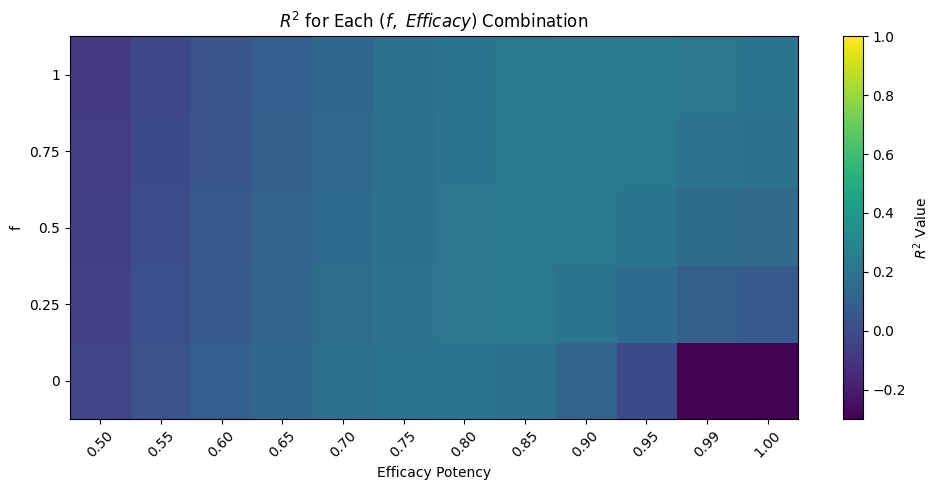

In [373]:
# ----------------------------
# Heatmap of all the f x eps combination (60 combos)
# ----------------------------

# Arrange R² values into a 5 × 12 matrix
# ----------------------------
r2_pivot = oselt_r2_results_df.pivot(
    index="f",
    columns="Efficacy",
    values="R2"
).sort_index()

plt.figure(figsize=(10, 5))

im = plt.imshow(
    r2_pivot.values,
    aspect="auto",
    origin="lower",
    interpolation="nearest",
    cmap="viridis",
    vmin=-0.3,
    vmax=1
)

plt.colorbar(im, label=r"$R^2$ Value")

plt.xticks(
    np.arange(len(r2_pivot.columns)),
    [f"{x:.2f}" for x in r2_pivot.columns],
    rotation=45
)

plt.yticks(
    np.arange(len(r2_pivot.index)),
    [f"{x:g}" for x in r2_pivot.index]
)

# Labeling
# ----------------------------
plt.xlabel("Efficacy Potency")
plt.ylabel("f")
plt.title(r"$R^2$ for Each $(f,\ Efficacy)$ Combination")

plt.tight_layout()
plt.show()

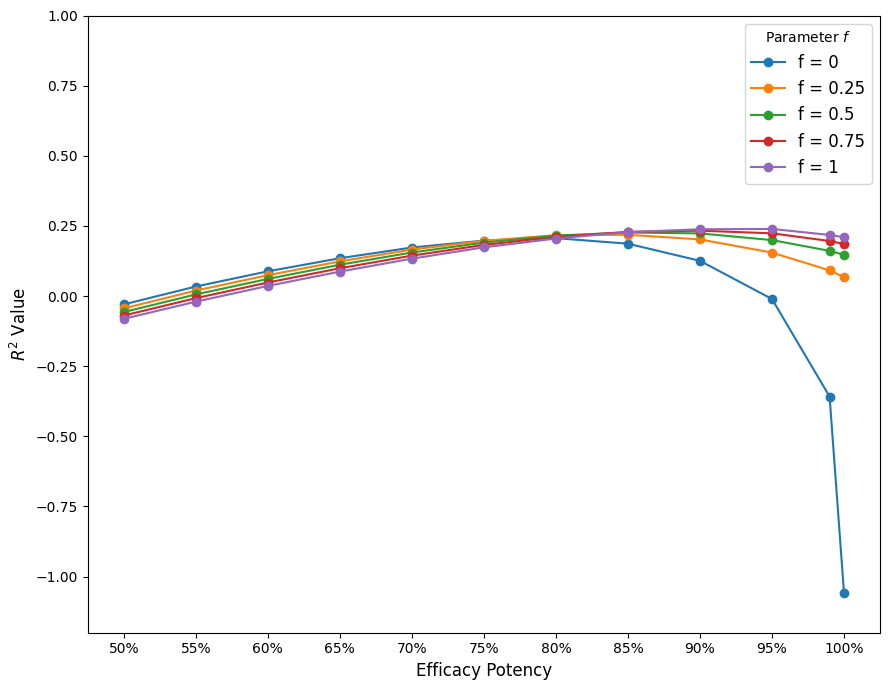

In [424]:
from matplotlib.ticker import PercentFormatter, MultipleLocator


efficacy_values = np.arange(0.5, 1.01, 0.05) #np.append(np.arange(0.5, 1.01, 0.05), 0.99)        # efficacy rate from 50% - 99% by increments of 5%


# Organize R2 values: rows = f, columns = Efficacy
r2_pivot = oselt_r2_results_df.pivot(
    index = "f",
    columns = "Efficacy",
    values = "R2"
).sort_index(axis=1)

fig, ax = plt.subplots(figsize = (9, 7))

# Plot one line for each f value
for f_value in r2_pivot.index:
    ax.plot(
        r2_pivot.columns,
        r2_pivot.loc[f_value],
        marker = "o",
        label=f"f = {f_value:g}"
    )

# Format efficacy values (0.5–1.0) as percentages
ax.xaxis.set_major_locator(MultipleLocator(0.05))
ax.xaxis.set_major_formatter(PercentFormatter(xmax=1.0))
ax.set_xlabel(r"Efficacy Potency", fontsize = 12)
ax.set_ylabel(r"$R^2$ Value", fontsize = 12)
ax.set_ylim(-1.2, 1)
ax.legend(title="Parameter $f$", fontsize = 12)
ax.grid(False)

plt.tight_layout()
plt.show()


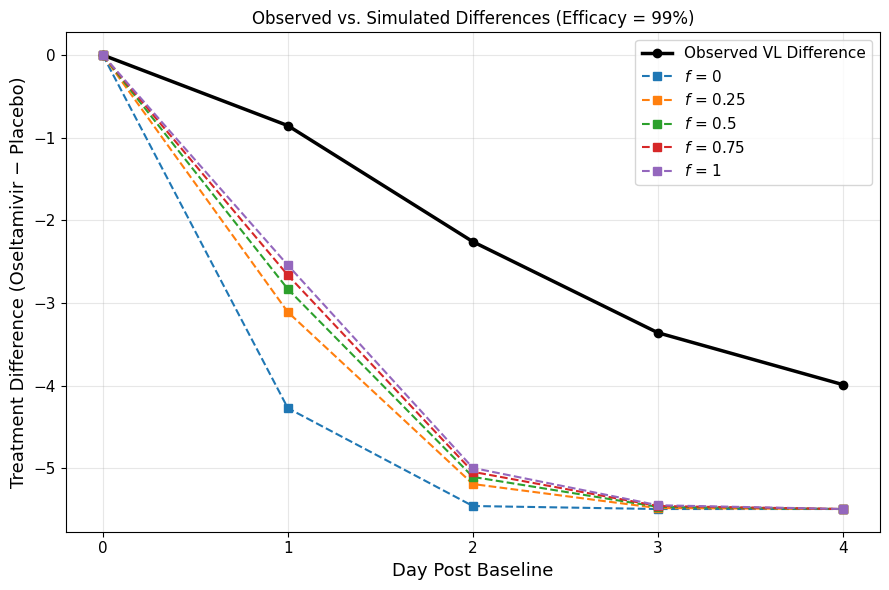

In [445]:

#-------------------------------
# Plotting the viral load drop from baseline compare to the NEJM obseved data
#-------------------------------

# print(oselt_mean.head())

days_to_analyze = [0, 1, 2, 3, 4]
observed_oselt_4days   = np.array([0, -2.5, -4.2, -4.6, -5])


#-------------------------------
# CHANGE efficacy value here
#-------------------------------
efficacy_to_plot = 0.99  # 99%; change as needed to see updated plot
#-------------------------------

# Filter observed data to Days 0–4
observed_plot = (
    observed_data_df[
        observed_data_df["Day"].isin(days_to_analyze)
    ]
    .sort_values("Day")
)

#-------------------------------
# Filter simulated data by efficacy and days
#-------------------------------
simulated_plot = oselt_mean[
    (oselt_mean["Efficacy"] == efficacy_to_plot) &
    (oselt_mean["Day"].isin(days_to_analyze))
].copy()

fig, ax = plt.subplots(figsize=(9, 6))

#-------------------------------
# Plot observed vl-difference values: oselt - placebo
#-------------------------------
ax.plot(
    observed_plot["Day"],
    observed_plot["Observed VL Difference"],
    marker="o",
    linestyle="-",
    color="black",
    linewidth=2.5,
    label="Observed VL Difference"
)

#-------------------------------
# Plot observed oselt-values 
#-------------------------------
#plt.plot(
#    days_to_analyze,
#    observed_oselt_4days,
#    marker='s',
#    linestyle='-',
#    color = 'magenta',
#    label = 'NEJM Oselt'
#)

#-------------------------------
# Plot one simulated curve for each f value; f = 0, 0.25, 0.5, 0.75, 1.00
#-------------------------------
for f_value, group in simulated_plot.groupby("f"):
    group = group.sort_values("Day")

    ax.plot(
        group["Day"],
        group["Mean Oselt VL Change"],
        marker="s",
        linestyle="--",
        label=f"$f$ = {f_value:g}"
    )

# labeling 
#-------------------------------
ax.set_xlabel("Day Post Baseline", fontsize=13)
ax.set_ylabel(
    "Treatment Difference (Oseltamivir − Placebo)",
    fontsize=13
)
ax.set_title(
    f"Observed vs. Simulated Differences (Efficacy = {efficacy_to_plot:.0%})"
)

ax.set_xticks(days_to_analyze)
ax.tick_params(axis="both", labelsize=11)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()